<a href="https://colab.research.google.com/github/rrdaks23/RS_Klimatologi/blob/main/UHI_Payakumbuh_2018-2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
# ==============================================================================
# 1. INSTALL & IMPORT LIBRARY
# ==============================================================================
!pip install geemap earthengine-api -q

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn as sns
from scipy.stats import pearsonr

# Autentikasi dan Inisialisasi Google Earth Engine
ee.Authenticate()
ee.Initialize(project='collaboration-512712')  # Ganti dengan Project ID GEE Anda

In [24]:
# ==============================================================================
# 2. DEFINISI AOI (ASSET GEE) & TAHUN PERBANDINGAN
# ==============================================================================
# Ganti dengan Asset ID SHP batas wilayah kota Anda di GEE
asset_path = 'projects/collaboration-512712/assets/Kota_Payakumbuh'

aoi_fc = ee.FeatureCollection(asset_path)
aoi = aoi_fc.geometry()

# Rentang Waktu Sesuai Permintaan
start_2018 = '2018-01-01'
end_2018 = '2018-12-31'

start_2026 = '2026-01-01'
end_2026 = '2026-10-31'

In [28]:
# ==============================================================================
# 3. FUNGSI PREPROCESSING & EKSTRAKSI CITRA
# ==============================================================================
# A. Sentinel-2 Cloud Masking & NDVI (Resolusi 10m)
def mask_s2_clouds(image):
    qa = image.select('QA60')
    cloud_bit_mask = 1 << 10
    cirrus_bit_mask = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(qa.bitwiseAnd(cirrus_bit_mask).eq(0))
    return image.updateMask(mask).divide(10000)

def get_ndvi(start_date, end_date, aoi):
    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(aoi)
          .filterDate(start_date, end_date)
          .map(mask_s2_clouds))  # Diperbolehkan menggunakan semua citra karena masker awan pixel-level sudah aman

    def add_ndvi(img):
        ndvi = img.normalizedDifference(['B8', 'B4']).rename('NDVI')
        return img.addBands(ndvi)

    return s2.map(add_ndvi).select('NDVI').median().clip(aoi)

# B. Landsat 8/9 Cloud Masking & LST Celcius (Resolusi 30m)
def mask_l8_sr(image):
    qa = image.select('QA_PIXEL')
    cloud_shadow = 1 << 4
    cloud = 1 << 3
    return image.updateMask(qa.bitwiseAnd(cloud_shadow).eq(0).And(qa.bitwiseAnd(cloud).eq(0)))

def get_lst(start_date, end_date, aoi):
    l8 = ee.ImageCollection('LANDSAT/LC08/C02/T1_L2').filterBounds(aoi).filterDate(start_date, end_date).map(mask_l8_sr)
    l9 = ee.ImageCollection('LANDSAT/LC09/C02/T1_L2').filterBounds(aoi).filterDate(start_date, end_date).map(mask_l8_sr)
    l_coll = l8.merge(l9)

    def calc_temp(img):
        thermal = img.select('ST_B10')
        lst_c = thermal.multiply(0.00341802).add(149.0).subtract(273.15).rename('LST')
        return img.select().addBands(lst_c)

    return l_coll.map(calc_temp).select('LST').median().clip(aoi)

# Eksekusi Pengambilan Data
print("Memproses data NDVI & LST untuk rentang tahun 2018 dan 2026...")
ndvi_2018 = get_ndvi(start_2018, end_2018, aoi)
ndvi_2026 = get_ndvi(start_2026, end_2026, aoi)

lst_2018 = get_lst(start_2018, end_2018, aoi)
lst_2026 = get_lst(start_2026, end_2026, aoi)

# Perhitungan Selisih (Change Detection)
ndvi_diff = ndvi_2026.subtract(ndvi_2018).rename('NDVI_Difference')
lst_diff = lst_2026.subtract(lst_2018).rename('LST_Difference')

Memproses data NDVI & LST untuk rentang tahun 2018 dan 2026...


In [29]:
# ==============================================================================
# 4. KUANTIFIKASI PERUBAHAN & ANALISIS LUAS AREA (HEKTAR)
# ==============================================================================
print("\n" + "="*50)
print("KUANTIFIKASI RATA-RATA WILAYAH (2018 vs 2026)")
print("="*50)

def safe_reduce(image, band_name, scale_val):
    dict_res = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=scale_val,
        maxPixels=1e9
    )
    val = dict_res.get(band_name)
    return ee.Algorithms.If(val, val, 0)

mean_n18 = safe_reduce(ndvi_2018, 'NDVI', 10).getInfo()
mean_n26 = safe_reduce(ndvi_2026, 'NDVI', 10).getInfo()
mean_l18 = safe_reduce(lst_2018, 'LST', 30).getInfo()
mean_l26 = safe_reduce(lst_2026, 'LST', 30).getInfo()

print(f"Rata-rata NDVI 2018 : {mean_n18:.4f}")
print(f"Rata-rata NDVI 2026 : {mean_n26:.4f} (Selisih: {mean_n26 - mean_n18:+.4f})")
print(f"Rata-rata LST 2018  : {mean_l18:.2f} °C")
print(f"Rata-rata LST 2026  : {mean_l26:.2f} °C (Selisih: {mean_l26 - mean_l18:+.2f} °C)")

# Klasifikasi Perubahan Vegetasi untuk Perhitungan Luas (Hektar)
# -1: Degradasi (< -0.1), 0: Stabil, 1: Pemulihan (> 0.1)
ndvi_class = ee.Image(0)\
    .where(ndvi_diff.lt(-0.1), -1)\
    .where(ndvi_diff.gt(0.1), 1)\
    .rename('Class')

area_image = ee.Image.pixelArea().divide(10000).addBands(ndvi_class)
area_stats = area_image.reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='class'),
    geometry=aoi,
    scale=10,
    maxPixels=1e9
).getInfo()

print("\n--- LUAS AREA PERUBAHAN VEGETASI (NDVI 10m) ---")
for item in area_stats.get('groups', []):
    cls = item['class']
    ha = item['sum']
    label = "Degradasi (< -0.1)" if cls == -1 else ("Stabil" if cls == 0 else "Pemulihan (> 0.1)")
    print(f"- {label}: {ha:.2f} Hektar")
print("="*50)


KUANTIFIKASI RATA-RATA WILAYAH (2018 vs 2026)
Rata-rata NDVI 2018 : 0.5775
Rata-rata NDVI 2026 : 0.5189 (Selisih: -0.0587)
Rata-rata LST 2018  : 31.92 °C
Rata-rata LST 2026  : 34.40 °C (Selisih: +2.48 °C)

--- LUAS AREA PERUBAHAN VEGETASI (NDVI 10m) ---
- Degradasi (< -0.1): 3024.05 Hektar
- Stabil: 3082.61 Hektar
- Pemulihan (> 0.1): 1453.81 Hektar



Mengekstrak sampel piksel untuk korelasi NDVI 2018 vs LST 2018 (°C)...
--------------------------------------------------
Korelasi NDVI 2018 vs LST 2018 (°C)
Pearson r : -0.4527 | p-value: 1.3810e-51
--------------------------------------------------


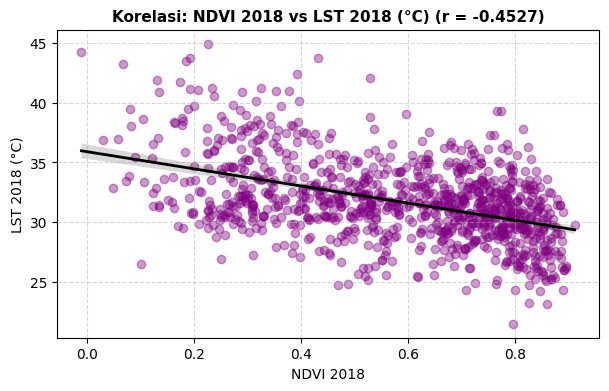


Mengekstrak sampel piksel untuk korelasi NDVI 2026 vs LST 2026 (°C)...
--------------------------------------------------
Korelasi NDVI 2026 vs LST 2026 (°C)
Pearson r : -0.5746 | p-value: 9.7406e-89
--------------------------------------------------


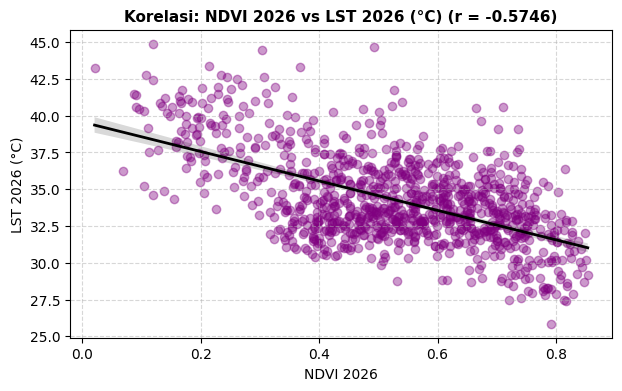


Mengekstrak sampel piksel untuk korelasi NDVI 2018 vs NDVI 2026...
--------------------------------------------------
Korelasi NDVI 2018 vs NDVI 2026
Pearson r : 0.5625 | p-value: 1.7075e-84
--------------------------------------------------


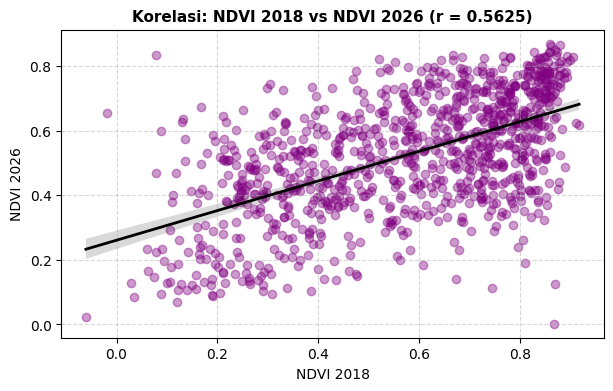


Mengekstrak sampel piksel untuk korelasi LST 2018 (°C) vs LST 2026 (°C)...
--------------------------------------------------
Korelasi LST 2018 (°C) vs LST 2026 (°C)
Pearson r : 0.8626 | p-value: 4.5306e-297
--------------------------------------------------


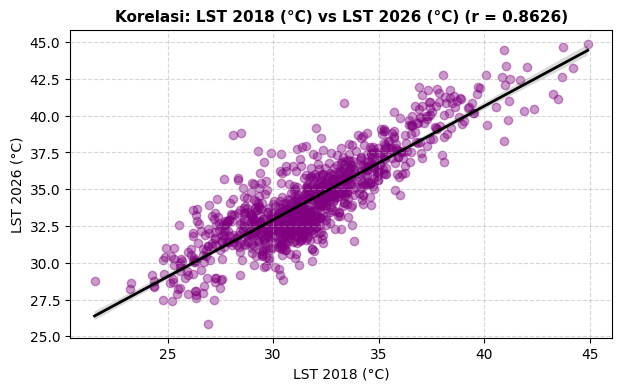

In [30]:
# ==============================================================================
# 5. ANALISIS KORELASI SPASIAL & TEMPORAL GANDA
# ==============================================================================
def run_correlation(img1, img2, label_x, label_y, scale_val):
    print(f"\nMengekstrak sampel piksel untuk korelasi {label_x} vs {label_y}...")
    combined_img = ee.Image.cat([img1.rename('VAR1'), img2.rename('VAR2')])

    sample_points = combined_img.sample(
        region=aoi,
        scale=scale_val,
        numPixels=1000,
        geometries=False
    )

    df_sample = sample_points.reduceColumns(
        reducer=ee.Reducer.toList().repeat(2),
        selectors=['VAR1', 'VAR2']
    ).getInfo()

    if df_sample['list'] and len(df_sample['list'][0]) > 0:
        v1 = df_sample['list'][0]
        v2 = df_sample['list'][1]

        df_corr = pd.DataFrame({'X': v1, 'Y': v2}).dropna()
        if len(df_corr) > 1:
            corr, p_value = pearsonr(df_corr['X'], df_corr['Y'])

            print("-"*50)
            print(f"Korelasi {label_x} vs {label_y}")
            print(f"Pearson r : {corr:.4f} | p-value: {p_value:.4e}")
            print("-"*50)

            plt.figure(figsize=(7, 4))
            sns.regplot(data=df_corr, x='X', y='Y', color='purple', scatter_kws={'alpha':0.4}, line_kws={'color':'black', 'linewidth':2})
            plt.title(f'Korelasi: {label_x} vs {label_y} (r = {corr:.4f})', fontsize=11, fontweight='bold')
            plt.xlabel(label_x, fontsize=10)
            plt.ylabel(label_y, fontsize=10)
            plt.grid(True, linestyle='--', alpha=0.5)
            plt.show()

# 1. Korelasi NDVI vs LST Tahun 2018
run_correlation(ndvi_2018, lst_2018, "NDVI 2018", "LST 2018 (°C)", 30)

# 2. Korelasi NDVI vs LST Tahun 2026
run_correlation(ndvi_2026, lst_2026, "NDVI 2026", "LST 2026 (°C)", 30)

# 3. Korelasi Antar-Tahun NDVI (2018 vs 2026) -> Pergeseran Pola Vegetasi
run_correlation(ndvi_2018, ndvi_2026, "NDVI 2018", "NDVI 2026", 10)

# 4. Korelasi Antar-Tahun LST (2018 vs 2026) -> Pergeseran Pola Suhu
run_correlation(lst_2018, lst_2026, "LST 2018 (°C)", "LST 2026 (°C)", 30)

In [31]:
# ==============================================================================
# 6. VISUALISASI PETA INTERAKTIF DI COLAB (DENGAN GOOGLE HYBRID)
# ==============================================================================
Map = geemap.Map()
Map.centerObject(aoi, 12)
Map.add_basemap('HYBRID')

Map.addLayer(aoi, {'color': 'cyan', 'strokeWidth': 2}, 'Batas Wilayah Studi', True)

ndvi_vis = {'min': 0.1, 'max': 0.7, 'palette': ['brown', 'yellow', 'green']}
lst_vis = {'min': 22, 'max': 38, 'palette': ['blue', 'cyan', 'yellow', 'orange', 'red']}

Map.addLayer(ndvi_2018, ndvi_vis, 'NDVI 2018 (Sentinel-2)', False)
Map.addLayer(ndvi_2026, ndvi_vis, 'NDVI 2026 (Sentinel-2)', False)
Map.addLayer(lst_2018, lst_vis, 'LST 2018 (°C)', False)
Map.addLayer(lst_2026, lst_vis, 'LST 2026 (°C)', True)

Map.addLayerControl()
display(Map)

Map(center=[-0.22673627768588728, 100.63197383157286], controls=(WidgetControl(options=['position', 'transpare…

In [32]:
# ==============================================================================
# 7. EKSPORT HASIL LENGKAP KE GOOGLE DRIVE (FOLDER: GEE_For porto)
# ==============================================================================
export_image = ee.Image.cat([
    ndvi_2018.rename('NDVI_2018'), ndvi_2026.rename('NDVI_2026'),
    lst_2018.rename('LST_2018'), lst_2026.rename('LST_2026'),
    ndvi_diff.rename('NDVI_Difference'), lst_diff.rename('LST_Difference'),
    ndvi_class
])

export_task = ee.batch.Export.image.toDrive(
    image=export_image,
    description='Penelitian_UHI_S2_Landsat_2018_2026',
    folder='GEE_For porto',
    fileNamePrefix='raster_analisis_uhi_sentinel_landsat_2018_2026',
    region=aoi,
    scale=10,  # Resolusi tertinggi Sentinel-2 (10 meter)
    maxPixels=1e9
)

export_task.start()
print("="*60)
print("Task ekspor seluruh layer raster (NDVI, LST, Selisih, & Kelas) berhasil diinisiasi!")
print("Folder Tujuan : 'GEE_For porto'")
print("Nama File     : 'raster_analisis_uhi_sentinel_landsat_2018_2026.tif'")
print("="*60)

Task ekspor seluruh layer raster (NDVI, LST, Selisih, & Kelas) berhasil diinisiasi!
Folder Tujuan : 'GEE_For porto'
Nama File     : 'raster_analisis_uhi_sentinel_landsat_2018_2026.tif'
